## 12\_modele\_scores\_rouen

# 12 · Potentiel Citiz des carreaux de Rouen

1. Réentraînement du modèle retenu (régression logistique) sur l'ensemble des réseaux Citiz, Strasbourg compris, avec le même périmètre d'exemples que la validation.
2. Score de chaque carreau de Rouen : `potentiel`, de 0 à 100, rang centile parmi les carreaux de la Métropole.
3. Population résidant à moins de 400 m d'une station Citiz existante, et taux d'adhésion qui en découle (majorant).

**Entrées :** `carreaux_apprentissage`, `variables_rouen` (notebook 10).

**Sorties :** tables `scores_rouen` et `stats_citiz` ; carte `Files/traite/cartes/potentiel_citiz_rouen.png`.

In [ ]:
# 1. Dépendances
%pip install -q geopandas pyogrio py7zr

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# 2. Outils communs
import os, re, glob, shutil, tempfile, zipfile, warnings
import numpy as np
import pandas as pd
from pyproj import Transformer
warnings.filterwarnings("ignore")

BASE = "/lakehouse/default/Files"
if not os.path.isdir(BASE):
    raise RuntimeError("Lakehouse par défaut non attaché : attacher le Lakehouse mobilite au notebook.")
BRUT = os.path.join(BASE, "brut")
TRAITE = os.path.join(BASE, "traite")
CARTES = os.path.join(TRAITE, "cartes")
os.makedirs(CARTES, exist_ok=True)

# Conversions entre systèmes de coordonnées : 3035 = grille INSEE, 2154 = Lambert-93 (mètres), 4326 = GPS
T_3035_2154 = Transformer.from_crs(3035, 2154, always_xy=True)
T_3035_4326 = Transformer.from_crs(3035, 4326, always_xy=True)
T_4326_3035 = Transformer.from_crs(4326, 3035, always_xy=True)
T_4326_2154 = Transformer.from_crs(4326, 2154, always_xy=True)

def _copier_csv(df, chemin):
    """Écrit le CSV en local, puis le copie dans le Lakehouse. Écrire directement dans OneLake échoue parfois
    quand le fichier existe déjà (« Unable to rename file »)."""
    fd, tmp = tempfile.mkstemp(suffix=".csv")
    os.close(fd)
    try:
        df.to_csv(tmp, index=False)
        if os.path.exists(chemin):
            os.remove(chemin)
        shutil.copyfile(tmp, chemin)
    finally:
        os.remove(tmp)

def _adresse_table(nom):
    """Adresse OneLake de la table dans le Lakehouse attaché, dans le schéma dbo s'il existe."""
    import notebookutils
    ctx = notebookutils.runtime.context
    espace = ctx.get("defaultLakehouseWorkspaceId") or ctx.get("currentWorkspaceId")
    lakehouse = ctx.get("defaultLakehouseId")
    if not (espace and lakehouse):
        raise RuntimeError("Lakehouse par défaut introuvable : attacher le Lakehouse mobilite au notebook")
    schema = "/dbo" if os.path.isdir("/lakehouse/default/Tables/dbo") else ""
    return f"abfss://{espace}@onelake.dfs.fabric.microsoft.com/{lakehouse}/Tables{schema}/{nom}"

def _ecrire_table(df, nom):
    """Table Delta lue par Power BI. Noyau Spark : saveAsTable. Noyau Python : bibliothèque deltalake."""
    try:
        spark  # n'existe que dans le noyau Spark
    except NameError:
        import pyarrow as pa
        import notebookutils
        from deltalake import write_deltalake
        donnees = pa.Table.from_pandas(df, preserve_index=False)
        options = {"bearer_token": notebookutils.credentials.getToken("storage"), "use_fabric_endpoint": "true"}
        try:
            write_deltalake(_adresse_table(nom), donnees, mode="overwrite", schema_mode="overwrite",
                            storage_options=options)
        except TypeError:   # anciennes versions de deltalake
            write_deltalake(_adresse_table(nom), donnees, mode="overwrite", overwrite_schema=True,
                            storage_options=options)
        return
    spark.createDataFrame(df).write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(nom)

def enregistrer(df, nom):
    """Enregistre un tableau en CSV dans Files/traite (relu par les autres notebooks)
    et en table du Lakehouse (lue par Power BI), avec le noyau Python comme avec le noyau Spark."""
    df = df.reset_index(drop=True).copy()
    _copier_csv(df, os.path.join(TRAITE, nom + ".csv"))
    for c in df.columns:
        if not (pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_bool_dtype(df[c])):
            df[c] = df[c].map(lambda v: None if v is None or (isinstance(v, float) and np.isnan(v)) else str(v))
    try:
        _ecrire_table(df, nom)
        print(f"   table {nom} : {len(df)} lignes (copie dans Files/traite/{nom}.csv)")
    except Exception as e:
        print(f"   {nom}.csv : {len(df)} lignes. ATTENTION, table non créée pour Power BI : {e}")

def nb(n):
    """Écrit un nombre avec des espaces entre les milliers : 12 345."""
    return f"{n:,.0f}".replace(",", " ")

def lire(nom):
    """Relit un tableau enregistré par un autre notebook."""
    chemin = os.path.join(TRAITE, nom + ".csv")
    if not os.path.exists(chemin):
        raise FileNotFoundError(f"{nom}.csv introuvable dans Files/traite : exécuter d'abord le notebook qui le produit.")
    return pd.read_csv(chemin, dtype={"idcar": str, "commune": str, "idcar_1km": str, "candidat": str})

COLONNES_FILOSOFI = ["idcar_200m", "idcar_1km", "i_est_200", "lcog_geo", "ind", "men", "men_pauv", "men_1ind",
                     "men_5ind", "men_prop", "men_fmp", "ind_snv", "men_surf", "men_coll", "men_mais", "log_av45",
                     "log_45_70", "log_70_90", "log_ap90", "log_inc", "log_soc", "ind_0_3", "ind_4_5", "ind_6_10",
                     "ind_11_17", "ind_18_24", "ind_25_39", "ind_40_54", "ind_55_64", "ind_65_79", "ind_80p", "ind_inc"]
TEXTE_FILOSOFI = ["idcar_200m", "idcar_1km", "lcog_geo"]

def charger_filosofi():
    """Carreaux de 200 m de métropole (CSV ou GeoPackage), avec leur centre en coordonnées 3035."""
    csvs = sorted(glob.glob(os.path.join(BRUT, "filosofi", "**", "*.csv"), recursive=True),
                  key=os.path.getsize, reverse=True)
    csvs = [c for c in csvs if "met" in os.path.basename(c).lower()] or csvs
    if csvs:
        source = csvs[0]
        with open(source, encoding="utf-8", errors="replace") as f:
            entete = f.readline()
        sep = ";" if entete.count(";") > entete.count(",") else ","
        noms = [c.strip().strip('"') for c in entete.strip().split(sep)]
        utiles = [c for c in noms if c.lower() in COLONNES_FILOSOFI]
        df = pd.read_csv(source, sep=sep, usecols=utiles,
                         dtype={c: str for c in utiles if c.lower() in TEXTE_FILOSOFI})
    else:
        gpkgs = [g for g in glob.glob(os.path.join(BRUT, "**", "*.gpkg"), recursive=True)
                 if "carreaux" in os.path.basename(g).lower() and "met" in os.path.basename(g).lower()]
        if not gpkgs:
            raise FileNotFoundError("Carreaux Filosofi introuvables dans Files/brut/filosofi (notebook 01).")
        import pyogrio
        source = gpkgs[0]
        df = pyogrio.read_dataframe(source, read_geometry=False)
    df.columns = [c.lower() for c in df.columns]
    df = df[[c for c in COLONNES_FILOSOFI if c in df.columns]].copy()
    for c in df.columns:
        if c not in TEXTE_FILOSOFI and not pd.api.types.is_numeric_dtype(df[c]):   # décimales avec une virgule
            df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", ".", regex=False), errors="coerce")
    nombres = [c for c in df.columns if c not in TEXTE_FILOSOFI]
    df[nombres] = df[nombres].fillna(0)
    # L'identifiant INSPIRE donne le coin sud-ouest du carreau en mètres : CRS3035RES200mN<nord>E<est>
    ne = df["idcar_200m"].astype(str).str.extract(r"CRS3035RES200mN(\d+)E(\d+)").astype(float)
    df["x3035"], df["y3035"] = ne[1] + 100, ne[0] + 100
    df = df.dropna(subset=["x3035", "y3035"])
    df["ix"] = ((df["x3035"] - 100) // 200).astype("int64")
    df["iy"] = ((df["y3035"] - 100) // 200).astype("int64")
    df["commune"] = df["lcog_geo"].astype(str).str[:5]
    df = df.rename(columns={"idcar_200m": "idcar"}).reset_index(drop=True)
    print(f"Filosofi : {nb(len(df))} carreaux de métropole lus ({os.path.basename(source)})")
    return df

def trouver_admin_express():
    """GeoPackage ADMIN EXPRESS : déjà extrait, ou extrait de l'archive .7z déposée dans Files/brut."""
    gpkgs = [g for g in glob.glob(os.path.join(BRUT, "**", "*.gpkg"), recursive=True)
             if "ADE" in os.path.basename(g).upper() or "ADMIN" in os.path.basename(g).upper()]
    if gpkgs:
        return gpkgs[0]
    archives = [a for a in glob.glob(os.path.join(BRUT, "**", "*.7z"), recursive=True) if "ADMIN" in a.upper()]
    if not archives:
        raise FileNotFoundError("Contours introuvables : fichiers IGN du notebook 01 ou archive ADMIN-EXPRESS (.7z) attendus dans Files/brut.")
    import py7zr
    with py7zr.SevenZipFile(sorted(archives)[-1], "r") as z:
        z.extractall(os.path.join(BRUT, "ign"))
    return trouver_admin_express()

def charger_territoire(court, mot):
    """Contour de l'intercommunalité (Lambert-93) et ses communes."""
    import geopandas as gpd
    f_epci = os.path.join(BRUT, f"epci_{court}.geojson")
    f_communes = os.path.join(BRUT, f"communes_{court}.geojson")
    if os.path.exists(f_epci) and os.path.exists(f_communes):
        epci = gpd.read_file(f_epci).to_crs(2154)
        communes = gpd.read_file(f_communes).to_crs(2154)
    else:
        gpkg = trouver_admin_express()
        epci = gpd.read_file(gpkg, layer="epci")
        epci = epci[epci["nom_officiel"].str.contains(mot, case=False, na=False)].to_crs(2154)
        siren = str(epci.iloc[0]["code_siren"])
        communes = gpd.read_file(gpkg, layer="commune")
        communes = communes[communes["codes_siren_des_epci"].astype(str).str.contains(siren, na=False)].to_crs(2154)
    contour = epci.geometry.iloc[0]
    communes = communes[["code_insee", "nom_officiel", "geometry"]].rename(
        columns={"code_insee": "commune", "nom_officiel": "commune_nom"})
    print(f"{epci.iloc[0]['nom_officiel']} : {len(communes)} communes, {contour.area / 1e6:.0f} km²")
    return contour, communes

def dans_contour(contour, x, y):
    """Vrai pour les points (Lambert-93) situés dans le contour."""
    import shapely
    xmin, ymin, xmax, ymax = contour.bounds
    resultat = np.zeros(len(x), dtype=bool)
    cadre = (x >= xmin) & (x <= xmax) & (y >= ymin) & (y <= ymax)
    shapely.prepare(contour)
    resultat[cadre] = shapely.contains_xy(contour, x[cadre], y[cadre])
    return resultat

In [ ]:
# 3. Réglages
# Modèle principal déclaré avant le test : régression logistique (explicable).
# Le gradient boosting n'intervient qu'à titre de comparaison (notebook 11).
MODELE = "logistique"
VARIABLES = ["pop_400", "menages_400", "part_25_39", "part_65_plus", "part_moins_18", "niveau_vie_400",
             "part_1_personne", "part_collectif", "part_proprietaires", "part_pauvres", "part_logement_social", "arrets_400"]

In [ ]:
# 4. Entraîner sur toutes les villes Citiz et noter Rouen
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
donnees = lire("carreaux_apprentissage")
rouen = lire("variables_rouen")
# Mêmes exemples que le test du notebook 11 : les carreaux des communes où Citiz est présent.
# Les communes de l'Eurométropole sans Citiz ne servent pas d'exemples « sans station ».
# (Une case vide du CSV revient en NaN, d'où le fillna avant le filtre.)
donnees["reseaux_commune"] = donnees["reseaux_commune"].fillna("").astype(str).replace("nan", "")
entrainement = donnees[donnees["reseaux_commune"] != ""]
print(f"Carreaux écartés (communes sans Citiz de l'Eurométropole) : {len(donnees) - len(entrainement)}")
if MODELE == "boosting":
    modele = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight="balanced", random_state=0)
else:
    modele = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
modele.fit(entrainement[VARIABLES].values, entrainement["station"].values)
rouen["proba"] = modele.predict_proba(rouen[VARIABLES].values)[:, 1]
rouen["potentiel"] = (100 * rouen["proba"].rank(pct=True)).round(1)
rouen["rang"] = rouen["proba"].rank(ascending=False, method="first").astype(int)
scores = rouen[["idcar", "commune", "lat", "lon", "ind", "proba", "potentiel", "rang"]].sort_values("rang")
print(f"Modèle entraîné sur {len(entrainement)} carreaux ({int(entrainement['station'].sum())} avec station). Rouen : {len(scores)} carreaux notés.")
print("Les 10 carreaux au plus fort potentiel :")
print(scores.head(10)[["idcar", "commune", "ind", "potentiel"]].to_string(index=False))
print("Enregistrement :")
enregistrer(scores, "scores_rouen")

Carreaux écartés (communes sans Citiz de l'Eurométropole) : 616
Modèle entraîné sur 65727 carreaux (1512 avec station). Rouen : 5727 carreaux notés.
Les 10 carreaux au plus fort potentiel :
                         idcar commune   ind  potentiel
CRS3035RES200mN2964400E3676600   76540 304.0      100.0
CRS3035RES200mN2964600E3676600   76540 421.0      100.0
CRS3035RES200mN2964400E3676800   76540 508.5      100.0
CRS3035RES200mN2964200E3676800   76540 303.5       99.9
CRS3035RES200mN2964600E3676400   76540 380.0       99.9
CRS3035RES200mN2964200E3677000   76540 526.0       99.9
CRS3035RES200mN2964600E3676800   76540 442.5       99.9
CRS3035RES200mN2964400E3677000   76540 418.5       99.9
CRS3035RES200mN2964800E3676600   76540 314.5       99.9
CRS3035RES200mN2964400E3676400   76540 478.0       99.8
Enregistrement :
   table scores_rouen : 5727 lignes (copie dans Files/traite/scores_rouen.csv)


In [ ]:
# 5. Population à moins de 400 m d'une station Citiz existante et taux d'adhésion
CLE = 1_000_000
VOISINS = [(dx, dy) for dx in range(-2, 3) for dy in range(-2, 3) if (dx * dx + dy * dy) * 200 ** 2 <= 400 ** 2]
grille = donnees.drop_duplicates("idcar").set_index(donnees.drop_duplicates("idcar")["ix"] * CLE + donnees.drop_duplicates("idcar")["iy"])["ind"]
avec_station = donnees[donnees["station"] == 1]
proches = {int(c + dx * CLE + dy) for c in (avec_station["ix"] * CLE + avec_station["iy"]) for dx, dy in VOISINS}
pop_400 = grille.reindex(list(proches)).fillna(0).sum()
stats = pd.DataFrame([{
    "stations_citiz": int(avec_station["nb_stations"].sum()),
    "population_a_400m_des_stations": round(pop_400),
    "conducteurs_citiz": 130000, "voitures_citiz": 2800,
    "taux_adhesion": round(130000 / max(pop_400, 1), 4),
    "conducteurs_par_voiture": round(130000 / 2800, 1),
}])
for cle, valeur in stats.iloc[0].items():
    print(f"   {cle} : {nb(valeur) if valeur >= 100 else valeur}")
print("Taux d'adhésion maximal : une partie des conducteurs Citiz vit à plus de 400 m d'une station, et seuls les "
      "carreaux des communes Citiz sont comptés : ordre de grandeur.")
enregistrer(stats, "stats_citiz")

   stations_citiz : 1 604
   population_a_400m_des_stations : 3 315 456
   conducteurs_citiz : 130 000
   voitures_citiz : 2 800
   taux_adhesion : 0.0392
   conducteurs_par_voiture : 46.4
Taux d'adhésion maximal : une partie des conducteurs Citiz vit à plus de 400 m d'une station, et seuls les carreaux des communes Citiz sont comptés : ordre de grandeur.
   table stats_citiz : 1 lignes (copie dans Files/traite/stats_citiz.csv)


Métropole Rouen Normandie : 71 communes, 664 km²


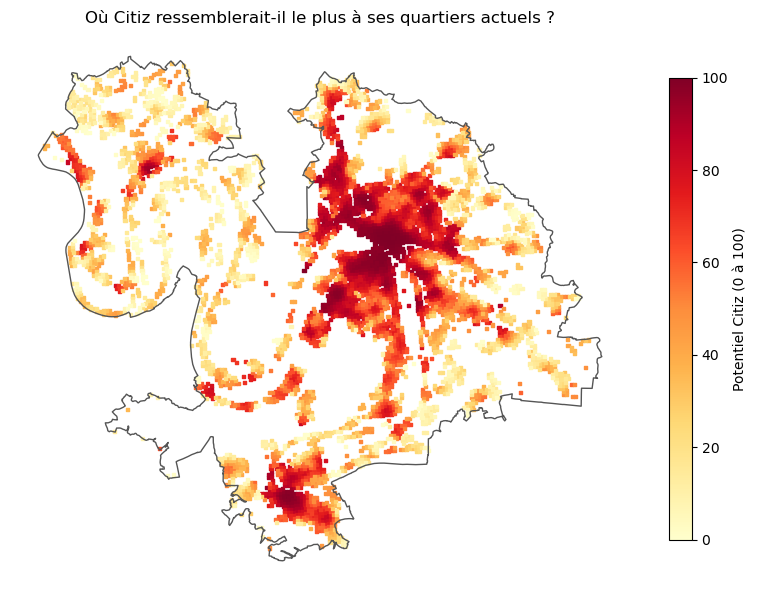

In [ ]:
# 6. Carte du potentiel (PNG)
import matplotlib.pyplot as plt
import geopandas as gpd
contour, _ = charger_territoire("rouen", "Rouen")
x, y = Transformer.from_crs(4326, 2154, always_xy=True).transform(scores["lon"].values, scores["lat"].values)
fig, ax = plt.subplots(figsize=(10, 10))
gpd.GeoSeries([contour], crs=2154).boundary.plot(ax=ax, color="#555555", linewidth=1)
sc = ax.scatter(x, y, c=scores["potentiel"], s=5, cmap="YlOrRd", marker="s")
plt.colorbar(sc, ax=ax, shrink=0.6, label="Potentiel Citiz (0 à 100)")
ax.set_title("Où Citiz ressemblerait-il le plus à ses quartiers actuels ?")
ax.set_axis_off()
plt.savefig(os.path.join(CARTES, "potentiel_citiz_rouen.png"), dpi=130, bbox_inches="tight")
plt.show()